# Braun et al. (2026), Fig. 2 — the connectivity profile tracks the target parameters (WP0.2)

> A: profiles for increasing offset (a = 0.5, σ = 1 s) become increasingly asymmetric. B: for increasing width
> (a = 0.5, b = 0) the range (max − min) decreases. C: for increasing amplitude (σ = 1 s, b = 0) an oscillation of
> increasing frequency appears.

**Panels:** A offset · B width · C amplitude (three profiles each, as in the paper) · D (added) every profile of each
sweep overlaid.

Profiles are those of the **mean matrix** over realisations (Braun Methods lines 979–990). Feature quantification is
in the Supp. 3 notebook; the 2-D grids in Supp. 4; motifs in Supp. 5.

**Settings:** dev (10 realisations, 100 + 10 iterations; spec D9). Final-setting runs replace them later.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv

style()
fig = Figure("wp0", "braun_fig2")
cfg = fig.config()
st = cfg["settings"]

def sweep(name, key):
    sw = cfg[name]
    out = []
    for v in sw["values"]:
        p = {k: sw[k] for k in ("amp", "width", "offset") if k in sw}
        p[key] = v
        r = wp0.get(p["amp"], p["width"], p["offset"], st)
        d, cp = cv.centred_profile(cv.profile_from_matrix(r.summary["mean_W"]))
        out.append(cp)
    return d, np.stack(out), np.array(sw["values"])

sweeps = {"offset": sweep("offset_sweep", "offset"), "width": sweep("width_sweep", "width"), "amplitude": sweep("amp_sweep", "amp")}
for name, (d, P, vals) in sweeps.items():
    fig.save(f"profiles_{name}", params=cfg[{"offset": "offset_sweep", "width": "width_sweep", "amplitude": "amp_sweep"}[name]], d=d, P=P, values=vals)

In [2]:
def three(panel, name, ylim):
    d = fig.load(f"profiles_{name}")
    sel = cfg["fig2_panels"][name]
    F, axs = plt.subplots(1, 3, figsize=(10, 2.4), sharey=True)
    for ax, v in zip(axs, sel):
        i = int(np.argmin(np.abs(d["values"] - v)))
        ax.plot(d["d"], d["P"][i], "k", lw=1.5); ax.axhline(0, color="tomato", ls="--"); ax.set_ylim(*ylim)
        ax.set_title(f"{name} = {d['values'][i]:g}"); ax.set_xlabel("neuron distance")
    axs[0].set_ylabel(r"$\langle W\rangle_N$")
    fig.savefig(panel, F); plt.show()

## Panel A — increasing offset (a = 0.5, σ = 1 s)

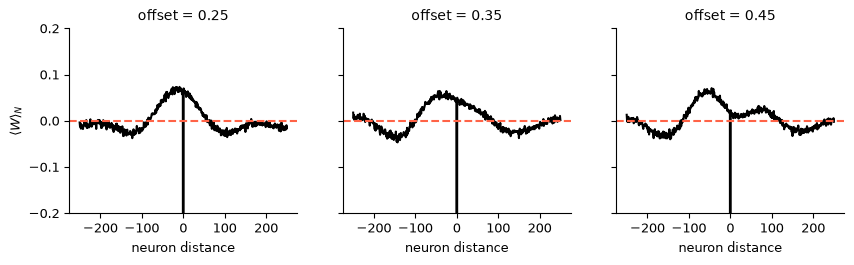

In [3]:
three("A_offset", "offset", (-0.2, 0.2))

## Panel B — increasing width (a = 0.5, b = 0)

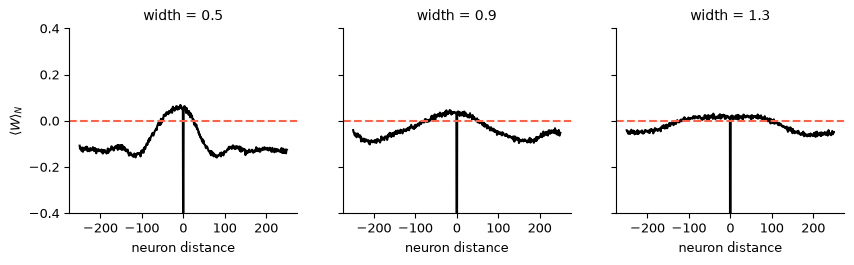

In [4]:
three("B_width", "width", (-0.4, 0.4))

## Panel C — increasing amplitude (σ = 1 s, b = 0)

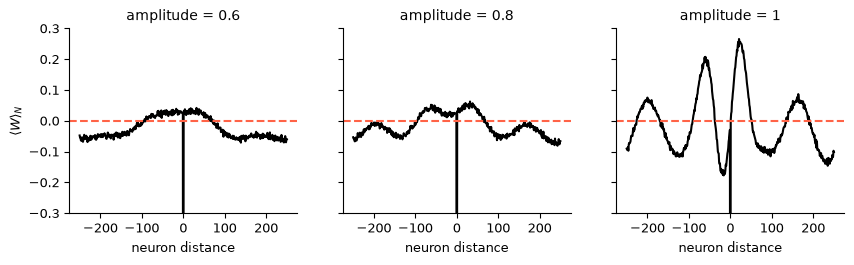

In [5]:
three("C_amplitude", "amplitude", (-0.3, 0.3))

## Panel D (added) — all profiles of each sweep (d = 0 replaced by the mean of d = ±1 for display)

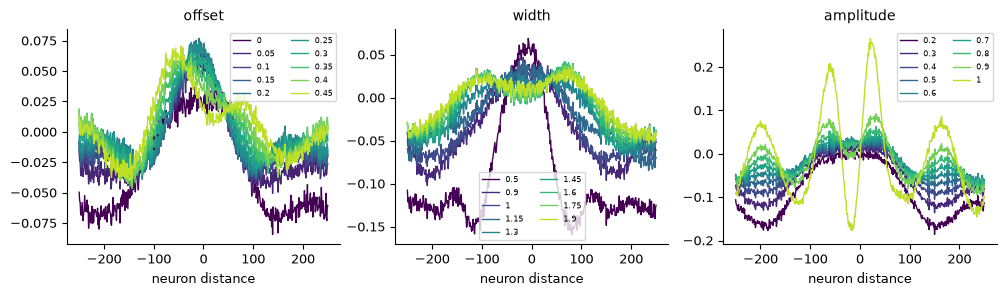

In [6]:
F, axs = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, name in zip(axs, ["offset", "width", "amplitude"]):
    d = fig.load(f"profiles_{name}")
    cols = plt.cm.viridis(np.linspace(0, 0.9, len(d["values"])))
    i0 = int(np.nonzero(d["d"] == 0)[0][0])
    for p, v, c in zip(d["P"], d["values"], cols):
        p = p.copy(); p[i0] = 0.5 * (p[i0 - 1] + p[i0 + 1])
        ax.plot(d["d"], p, color=c, lw=1, label=f"{v:g}")
    ax.set_title(name); ax.legend(fontsize=6, ncol=2); ax.set_xlabel("neuron distance")
fig.savefig("D_all_profiles", F); plt.show()

## Acceptance (qualitative; quantitative feature trends are checked in the Supp. 3 notebook)

In [7]:
fig.checks([{"item": "profiles produced for all sweep values", "criterion": "reported (visual comparison with Fig. 2)",
             "value": {k: len(fig.load(f"profiles_{k}")["values"]) for k in ["offset", "width", "amplitude"]}, "passed": None}])

[info] profiles produced for all sweep values: {'offset': 10, 'width': 9, 'amplitude': 9}


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig2/acceptance.json')